# 04 · Results

Everything here is read from the logs (copy them from the lab GPU first:
`rsync -av labblackwell:~/ege/cl-relearning/logs/ logs/`). Metrics come from `src/metrics.py`.
Test-set numbers are reported here; nothing in this notebook is used to choose settings.

In [1]:
import os, sys                                  # paths
from pathlib import Path
import numpy as np                              # numbers
import pandas as pd                             # tables
import matplotlib.pyplot as plt                 # plots

sys.path.insert(0, "../src")                    # so we can import metrics.py
import metrics as M

LOGS = Path(os.environ.get("CL_LOGS", "../logs"))      # the copied logs
COLORS = {"A": "#2b59c3", "B": "#7a7f88", "C": "#c2701d"}   # same arm colours as the recipe page
NAMES = {"A": "A · learned CIFAR-10", "B": "B · never learned", "C": "C · learned CIFAR-100"}
SUBSET_NAMES = {"never_seen": "never-seen 5k", "a_seen": "A-seen 5k"}
pd.set_option("display.precision", 4)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "lines.linewidth": 2})

## 1. Stage 1: learning

In [2]:
s1 = M.load_stage(1, LOGS)
final1 = s1.sort_values("step").groupby(["arm", "seed"]).tail(1)
print("Test accuracy at the end of stage 1 (A: CIFAR-10, C: CIFAR-100)")
final1.pivot(index="arm", columns="seed", values="test_acc").assign(mean=lambda t: t.mean(axis=1))

Test accuracy at the end of stage 1 (A: CIFAR-10, C: CIFAR-100)


seed,1,2,3,mean
arm,,,,
A,0.9498,0.9489,0.9474,0.9487
C,0.7709,0.7630,0.7661,0.7667


In [3]:
probes = M.load_probes(LOGS)
print("CIFAR-10 probe before stage 2 (B: at its random start)")
probes.pivot(index="arm", columns="seed", values="probe_acc").assign(mean=lambda t: t.mean(axis=1))

CIFAR-10 probe before stage 2 (B: at its random start)


seed,1,2,3,mean
arm,,,,
A,0.9479,0.9464,0.9466,0.9470
B,0.3575,0.3639,0.3497,0.3570
C,0.7195,0.7117,0.7098,0.7137


## 2. Stage 2: forgetting

SVHN accuracy, the old head (A on CIFAR-10, C on CIFAR-100) and the CIFAR-10 probe, mean ± spread across seeds.

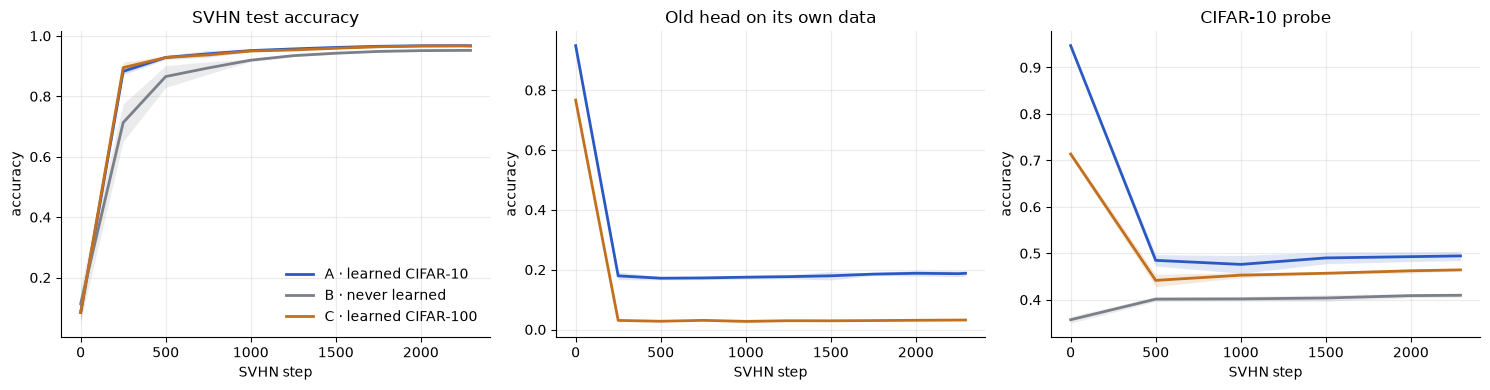

In [4]:
s2 = M.load_stage(2, LOGS)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ["svhn_acc", "old_acc", "probe_acc"],
                          ["SVHN test accuracy", "Old head on its own data", "CIFAR-10 probe"]):
    for arm in M.ARMS:
        d = s2[(s2.arm == arm)].dropna(subset=[col]) if col in s2 else pd.DataFrame()
        if d.empty:
            continue
        g = d.groupby("step")[col].agg(["mean", "std"]).reset_index()
        ax.plot(g["step"], g["mean"], color=COLORS[arm], label=NAMES[arm])
        ax.fill_between(g["step"], g["mean"] - g["std"], g["mean"] + g["std"], color=COLORS[arm], alpha=0.15, lw=0)
    ax.set_title(title); ax.set_xlabel("SVHN step"); ax.set_ylabel("accuracy")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

In [5]:
end2 = s2.sort_values("step").groupby(["arm", "seed"]).tail(1)
cols = [c for c in ["svhn_acc", "old_acc", "probe_acc"] if c in end2]
print("End of stage 2 (mean across seeds)")
end2.groupby("arm")[cols].agg(["mean", "std"])

End of stage 2 (mean across seeds)


svhn_acc         old_acc         probe_acc        
        mean     std    mean     std      mean     std
arm                                                   
A     0.9673  0.0011  0.1878  0.0093    0.4944  0.0099
B     0.9519  0.0003     NaN     NaN    0.4097  0.0043
C     0.9662  0.0005  0.0317  0.0008    0.4644  0.0021

## 3. Stage 3: relearning curves (the main result)

Smoothed test accuracy (3-point running mean), mean ± spread across seeds.

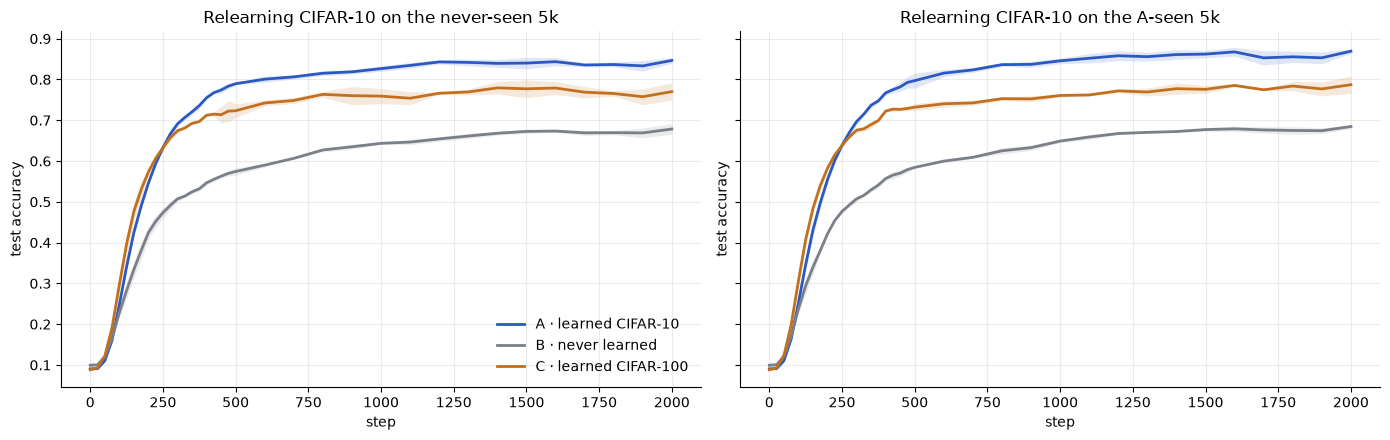

In [6]:
s3 = M.load_stage3(LOGS)
mc = M.mean_curves(s3)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, subset in zip(axes, M.SUBSETS[::-1]):
    for arm in M.ARMS:
        g = mc[(mc.subset == subset) & (mc.arm == arm)]
        ax.plot(g["step"], g["mean"], color=COLORS[arm], label=NAMES[arm])
        ax.fill_between(g["step"], g["mean"] - g["std"], g["mean"] + g["std"], color=COLORS[arm], alpha=0.15, lw=0)
    ax.set_title(f"Relearning CIFAR-10 on the {SUBSET_NAMES[subset]}"); ax.set_xlabel("step"); ax.set_ylabel("test accuracy")
axes[0].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

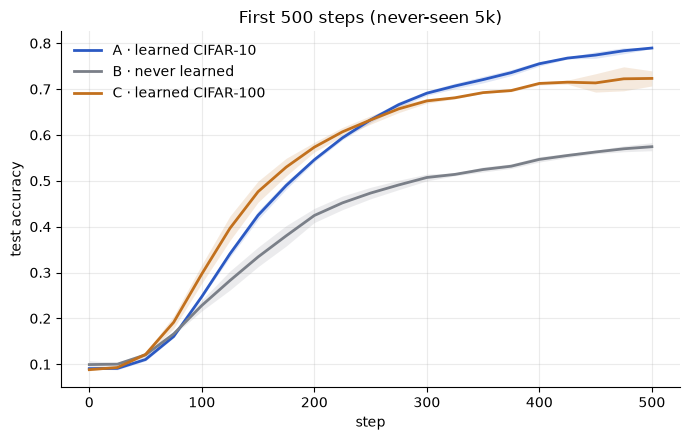

In [7]:
# zoom on the first 500 steps, where the arms differ most
fig, ax = plt.subplots(figsize=(7, 4.5))
for arm in M.ARMS:
    g = mc[(mc.subset == "never_seen") & (mc.arm == arm) & (mc.step <= 500)]
    ax.plot(g["step"], g["mean"], color=COLORS[arm], label=NAMES[arm])
    ax.fill_between(g["step"], g["mean"] - g["std"], g["mean"] + g["std"], color=COLORS[arm], alpha=0.15, lw=0)
ax.set_title("First 500 steps (never-seen 5k)"); ax.set_xlabel("step"); ax.set_ylabel("test accuracy")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 3b. The whole timeline, one arm per row

Every arm through all three stages, mean ± spread across seeds.
- **Stages 1–2 (left):** the thick line is the CIFAR-10 probe (frozen features, same test for every arm). In stage 1 it was only measured at the start and the end, so those two points are joined by a dotted line. The thin line is the training head on its own test set (A: CIFAR-10, C: CIFAR-100), for context.
- **Stage 3 (right, zoomed):** CIFAR-10 test accuracy of the fresh relearn head. Solid = relearning on the A-seen 5k (images A trained on in stage 1; new to B and C), dashed = on the never-seen 5k (no arm saw them).

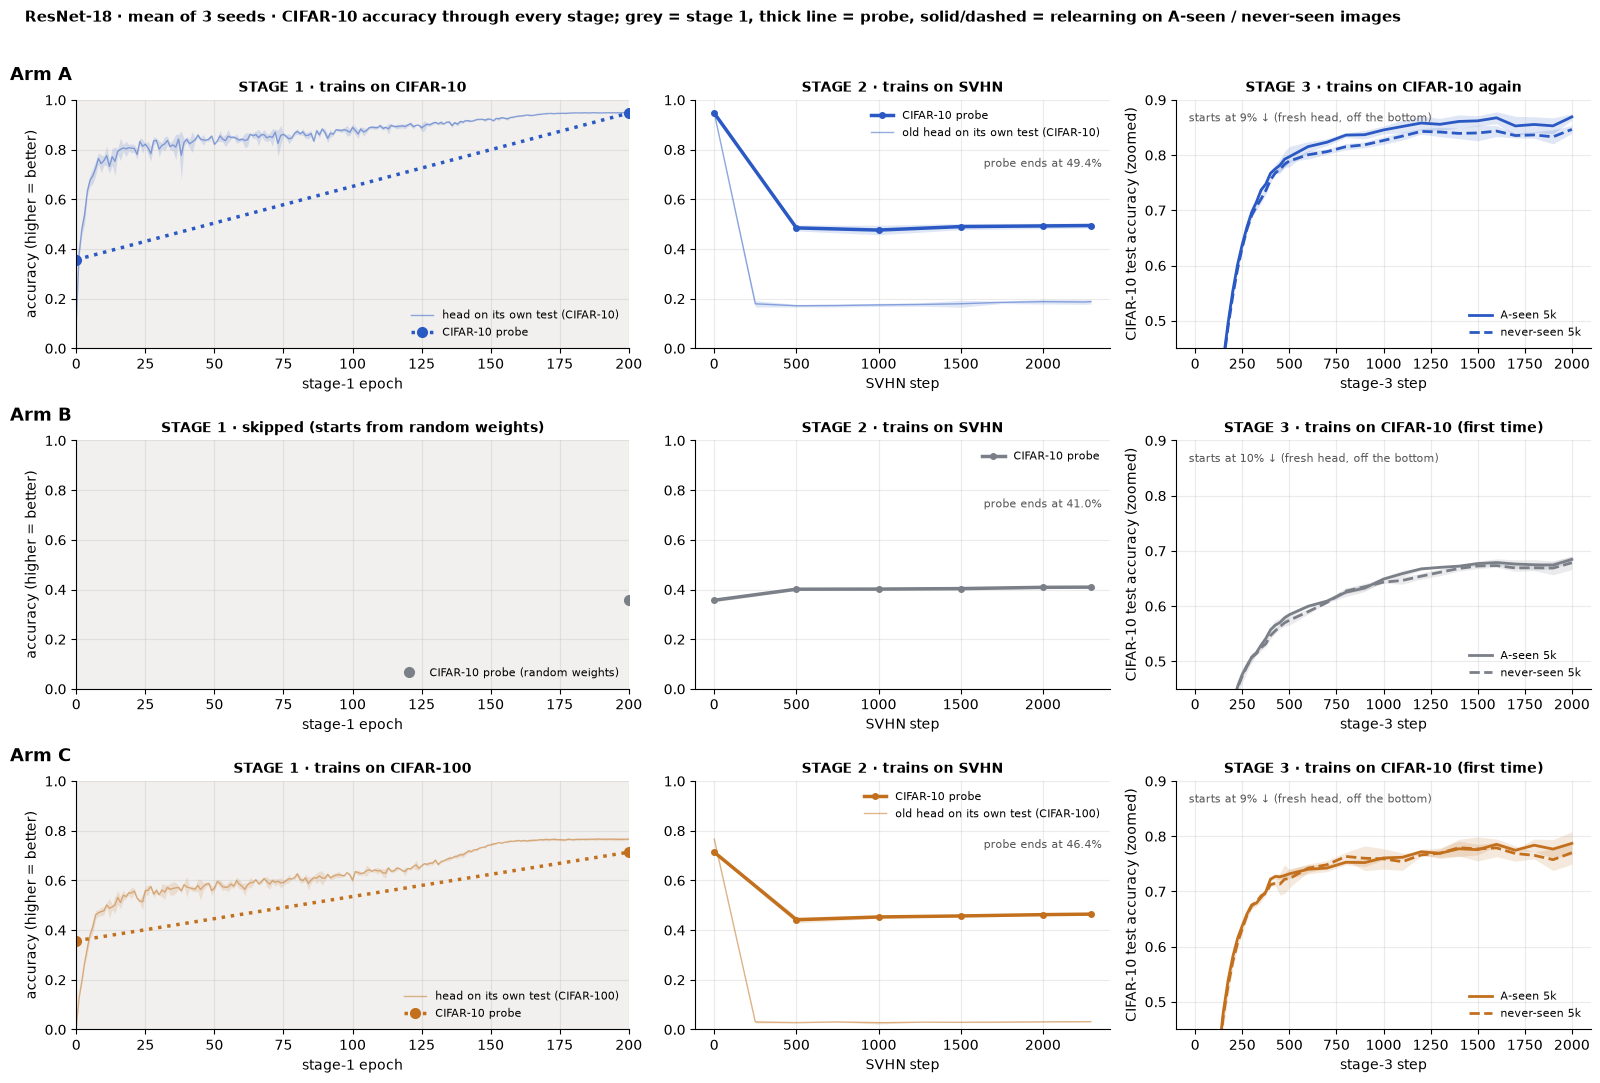

In [8]:
s1 = M.load_stage(1, LOGS)                       # stage-1 curves (A and C only)
probes = M.load_probes(LOGS)                     # probe at the end of stage 1 (A, C) and at B's random start
start_probe = probes[probes.stage == 0].probe_acc.mean()   # untrained network: also A's and C's stage-1 start
mc = M.mean_curves(M.load_stage3(LOGS))          # smoothed stage-3 curves
STAGE1 = {"A": "STAGE 1 · trains on CIFAR-10", "B": "STAGE 1 · skipped (starts from random weights)",
          "C": "STAGE 1 · trains on CIFAR-100"}
ZOOM = (0.45, 0.9)                               # stage-3 y range

def band(d, x, col):
    """Mean and std across seeds at every x."""
    return d.groupby(x)[col].agg(["mean", "std"]).reset_index()

def draw(ax, g, x, color, **kw):
    ax.plot(g[x], g["mean"], color=color, **kw)
    ax.fill_between(g[x], g["mean"] - g["std"], g["mean"] + g["std"], color=color, alpha=0.15, lw=0)

fig, axes = plt.subplots(3, 3, figsize=(16, 11), gridspec_kw={"width_ratios": [2, 1.5, 1.5]})
for row, arm in zip(axes, M.ARMS):
    c = COLORS[arm]
    ax1, ax2, ax3 = row

    # stage 1: grey band, probe at start and end, the head's own test accuracy
    ax1.set_facecolor("#f1f0ee")
    end = probes[(probes.arm == arm) & (probes.stage == 1)].probe_acc.mean() if arm != "B" else None
    if arm != "B":
        g = band(s1[s1.arm == arm], "epoch", "test_acc")
        own = "CIFAR-10" if arm == "A" else "CIFAR-100"
        draw(ax1, g, "epoch", c, lw=1, alpha=0.5, label=f"head on its own test ({own})")
        ax1.plot([0, 200], [start_probe, end], ":", color=c, lw=2.5, marker="o", ms=7, label="CIFAR-10 probe")
        ax1.set_xlim(0, 200)
    else:
        ax1.plot([200], [start_probe], "o", color=c, ms=7, label="CIFAR-10 probe (random weights)")
        ax1.set_xlim(0, 200)
    ax1.set_title(STAGE1[arm], fontsize=10, fontweight="bold")
    ax1.set_xlabel("stage-1 epoch"); ax1.set_ylabel("accuracy (higher = better)")
    ax1.set_ylim(0, 1); ax1.legend(frameon=False, loc="lower right", fontsize=8)
    ax1.text(-0.12, 1.08, f"Arm {arm}", transform=ax1.transAxes, fontsize=13, fontweight="bold")

    # stage 2: probe (thick) and the old head (thin)
    d2 = s2[s2.arm == arm]
    draw(ax2, band(d2.dropna(subset=["probe_acc"]), "step", "probe_acc"), "step", c, lw=2.5, marker="o", ms=4,
         label="CIFAR-10 probe")
    if d2["old_acc"].notna().any():
        draw(ax2, band(d2.dropna(subset=["old_acc"]), "step", "old_acc"), "step", c, lw=1, alpha=0.5,
             label=f"old head on its own test ({'CIFAR-10' if arm == 'A' else 'CIFAR-100'})")
    ax2.set_title("STAGE 2 · trains on SVHN", fontsize=10, fontweight="bold")
    ax2.set_xlabel("SVHN step"); ax2.set_ylim(0, 1); ax2.legend(frameon=False, loc="upper right", fontsize=8)
    ax2.text(0.98, 0.72, f"probe ends at {d2.groupby('seed').probe_acc.last().mean():.1%}",
             transform=ax2.transAxes, ha="right", va="bottom", fontsize=8, color="#555")

    # stage 3: relearning, zoomed; solid = A-seen, dashed = never-seen
    for subset, ls in [("a_seen", "-"), ("never_seen", "--")]:
        g = mc[(mc.subset == subset) & (mc.arm == arm)]
        draw(ax3, g, "step", c, ls=ls, label=SUBSET_NAMES[subset])
    first = mc[(mc.arm == arm) & (mc.step == 0)]["mean"].mean()
    ax3.set_ylim(*ZOOM)
    ax3.text(0.03, 0.95, f"starts at {first:.0%} ↓ (fresh head, off the bottom)",
             transform=ax3.transAxes, fontsize=8, color="#555", va="top")
    again = "again" if arm == "A" else "(first time)"
    ax3.set_title(f"STAGE 3 · trains on CIFAR-10 {again}", fontsize=10, fontweight="bold")
    ax3.set_xlabel("stage-3 step"); ax3.set_ylabel("CIFAR-10 test accuracy (zoomed)")
    ax3.legend(frameon=False, loc="lower right", fontsize=8)

fig.suptitle("ResNet-18 · mean of 3 seeds · CIFAR-10 accuracy through every stage; "
             "grey = stage 1, thick line = probe, solid/dashed = relearning on A-seen / never-seen images",
             fontsize=11, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## 4. Metrics

`steps_to_X`: first step where the smoothed curve reaches X% (n_reached = how many seeds got there). `auc`: average accuracy over the whole relearning. `final_acc`: mean of the last 500 steps. `gain_after_50`: accuracy gained in the 500 steps after first reaching 50%.

In [9]:
runs = M.per_run(s3)
M.summary(runs)

auc         final_acc         gain_after_50          \
                  mean     std      mean     std          mean     std   
subset     arm                                                           
a_seen     A    0.7828  0.0053    0.8611  0.0087        0.2869  0.0185   
           B    0.6034  0.0022    0.6804  0.0043        0.1149  0.0091   
           C    0.7185  0.0048    0.7809  0.0099        0.2030  0.0167   
never_seen A    0.7665  0.0041    0.8410  0.0056        0.2605  0.0059   
           B    0.5979  0.0052    0.6738  0.0086        0.1208  0.0036   
           C    0.7141  0.0061    0.7695  0.0055        0.2186  0.0205   

               steps_to_50                    steps_to_70                     \
                      mean n_reached      std        mean n_reached      std   
subset     arm                                                                 
a_seen     A      191.6667         3  14.4338    316.6667         3  14.4338   
           B      308.3333         3  14.4338         NaN         0      NaN   
           C      175.0000         3   0.0000    391.6667         3  14.4338   
never_seen A      200.0000         3   0.0000    325.0000         3   0.0000   
           B      300.0000         3  25.0000         NaN         0      NaN   
           C      175.0000         3   0.0000    400.0000         3   0.0000   

               steps_to_80                     
                      mean n_reached      std  
subset     arm                                 
a_seen     A      525.0000         3  66.1438  
           B           NaN         0      NaN  
           C     2000.0000         1      NaN  
never_seen A      633.3333         3  57.7350  
           B           NaN         0      NaN  
           C     1500.0000         1      NaN

## 5. Key comparisons (never-seen subset)

Per-seed differences. A difference is convincing when its mean is clearly larger than its spread across seeds.

In [10]:
rows = []
for metric in ["auc", "final_acc", "steps_to_50", "steps_to_70"]:
    for a, b in [("A", "C"), ("A", "B"), ("C", "B")]:
        d, mean, sd = M.differences(runs, metric, a, b)
        rows.append({"metric": metric, "comparison": f"{a} − {b}", "per seed": np.round(d.to_numpy(), 4).tolist(),
                     "mean": mean, "std": sd})
pd.DataFrame(rows)

,metric,comparison,per seed,mean,std
0,auc,A − C,"[0.0571, 0.0446, 0.0555]",0.0524,0.0068
1,auc,A − B,"[0.1786, 0.1621, 0.1649]",0.1685,0.0088
2,auc,C − B,"[0.1215, 0.1174, 0.1094]",0.1161,0.0061
3,final_acc,A − C,"[0.081, 0.065, 0.0686]",0.0716,0.0084
4,final_acc,A − B,"[0.1799, 0.1575, 0.1643]",0.1672,0.0115
5,final_acc,C − B,"[0.0988, 0.0924, 0.0957]",0.0956,0.0032
6,steps_to_50,A − C,"[25.0, 25.0, 25.0]",25.0000,0.0000
7,steps_to_50,A − B,"[-125.0, -100.0, -75.0]",-100.0000,25.0000
8,steps_to_50,C − B,"[-150.0, -125.0, -100.0]",-125.0000,25.0000
9,steps_to_70,A − C,"[-75.0, -75.0, -75.0]",-75.0000,0.0000


## 6. Aligned curves: started ahead, or learns faster?

Each curve starts where it first reaches 50%. If the curves overlap after alignment, an arm only started ahead; if one still rises faster, it truly learns faster.

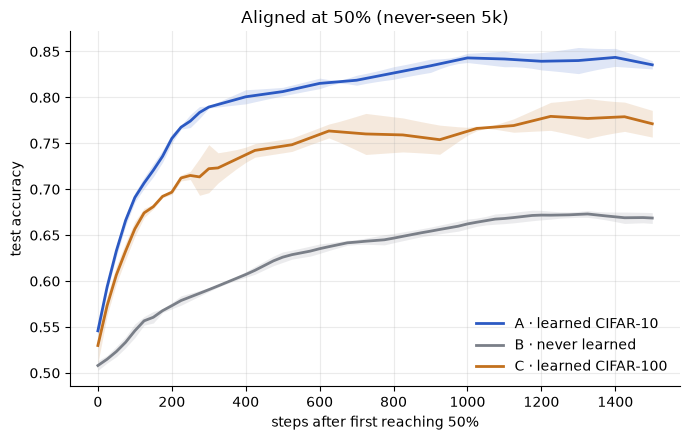

In [11]:
al = M.aligned_curves(s3, start_at=0.5)
fig, ax = plt.subplots(figsize=(7, 4.5))
for arm in M.ARMS:
    g = al[(al.subset == "never_seen") & (al.arm == arm)]
    if g.empty:
        continue
    ax.plot(g["step_from_start"], g["mean"], color=COLORS[arm], label=NAMES[arm])
    ax.fill_between(g["step_from_start"], g["mean"] - g["std"], g["mean"] + g["std"], color=COLORS[arm], alpha=0.15, lw=0)
ax.set_title("Aligned at 50% (never-seen 5k)"); ax.set_xlabel("steps after first reaching 50%"); ax.set_ylabel("test accuracy")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 7. Memory effect: does A remember its own images?

gap = result on A-seen − result on never-seen (per arm). memory effect = gap(A) − gap(B), and gap(A) − gap(C). B and C never trained on CIFAR-10 images, so their gap measures how much easier the A-seen subset is by itself.

In [12]:
for metric in ["auc", "final_acc"]:
    me = M.memory_effect(runs, metric)
    print(f"--- {metric}")
    display(me.assign().round(4))
    print("mean:", me[["effect_vs_B", "effect_vs_C"]].mean().round(4).to_dict(),
          "| std:", me[["effect_vs_B", "effect_vs_C"]].std().round(4).to_dict())

--- auc


,gap_A,gap_B,gap_C,effect_vs_B,effect_vs_C
seed,,,,,
1,0.0083,0.0101,0.0096,-0.0018,-0.0013
2,0.0241,-0.0010,-0.0024,0.0251,0.0265
3,0.0166,0.0073,0.0061,0.0093,0.0105


mean: {'effect_vs_B': 0.0109, 'effect_vs_C': 0.0119} | std: {'effect_vs_B': 0.0135, 'effect_vs_C': 0.014}
--- final_acc


,gap_A,gap_B,gap_C,effect_vs_B,effect_vs_C
seed,,,,,
1,0.0074,0.0109,0.0262,-0.0034,-0.0188
2,0.0300,-0.0053,0.0021,0.0353,0.0279
3,0.0228,0.0142,0.0061,0.0085,0.0167


mean: {'effect_vs_B': 0.0135, 'effect_vs_C': 0.0086} | std: {'effect_vs_B': 0.0198, 'effect_vs_C': 0.0243}


## 8. What was kept vs how fast it came back

Probe after stage 2 against relearning (area under the curve, never-seen). High probe and high AUC → kept knowledge is used; high probe but low AUC → kept but lost early in stage 3.

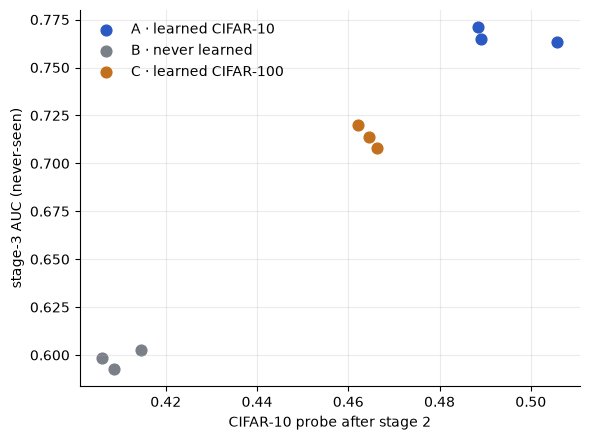

,arm,seed,probe_acc,auc
0,B,1,0.4086,0.5925
1,B,2,0.4145,0.6028
2,A,2,0.4890,0.7648
3,B,3,0.4061,0.5986
4,A,3,0.5058,0.7635
5,C,2,0.4622,0.7202
6,C,1,0.4645,0.7140
7,A,1,0.4884,0.7711
8,C,3,0.4664,0.7080


In [13]:
p2 = end2[["arm", "seed", "probe_acc"]]
r3 = runs[runs.subset == "never_seen"][["arm", "seed", "auc"]]
both = p2.merge(r3, on=["arm", "seed"])
fig, ax = plt.subplots(figsize=(6, 4.5))
for arm in M.ARMS:
    d = both[both.arm == arm]
    ax.scatter(d["probe_acc"], d["auc"], color=COLORS[arm], s=60, label=NAMES[arm])
ax.set_xlabel("CIFAR-10 probe after stage 2"); ax.set_ylabel("stage-3 AUC (never-seen)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
both

## Findings

**The question:** if a network learns something and then "forgets" it by learning something else, is the old knowledge really gone, or does it come back faster when the network learns it again?

**The setup in one line:** three copies of the same network, ResNet-18, an image classifier.
- **A** learned CIFAR-10 (photos of 10 kinds of objects).
- **C** learned CIFAR-100 (photos of 100 other kinds of objects).
- **B** learned nothing.

Then all three learned SVHN (photos of house numbers), which overwrote what they knew. Finally, all three relearned CIFAR-10 from only 5,000 images. Every result below is the average of 3 repeats (seeds).

### What we found

**1. Learning worked.** After the first stage, A recognised CIFAR-10 photos correctly 94.9% of the time and C got 76.7% on CIFAR-100.

**2. Forgetting looked almost complete.** After training on house numbers:
- A's original CIFAR-10 classifier dropped from 94.9% to 18.8% (10% is pure guessing).
- C's CIFAR-100 classifier dropped to 3.2% (1% is guessing).
- Most of this happened within the first ~250 training steps.

A second check, the *probe*, asks how much CIFAR-10 information is still inside the network: we freeze the network and fit a simple classifier on top of what it computes. By the probe, A kept 49%, C 46% and B 41%. So the three arms looked fairly similar.

**3. But on relearning, A was clearly best. This is the main result.** Accuracy after relearning CIFAR-10 from 5,000 images:

| | Final accuracy | Average over the whole relearning |
|---|---|---|
| **A** (had learned CIFAR-10) | **84.1%** | **76.6%** |
| **C** (had learned other photos) | 77.0% | 71.4% |
| **B** (had learned nothing) | 67.4% | 59.8% |

- **A beat C by about 7 points in every repeat** (+8.1, +6.5, +6.9). The repeats differ by less than 1 point, so this is not luck.
- **A beat B by about 17 points.**
- **Only A reached 80%** in every repeat, after about 630 steps. C got there once in three repeats, and B never did.

**4. The forgotten knowledge was hidden, not erased.** Before relearning, the probe showed A only ~3 points ahead of C. After relearning, A was ~7 points ahead. The network kept more of CIFAR-10 than a snapshot could show, and relearning brought it back out.

**5. A doesn't just start ahead; it learns faster.**
- Curiously, C is slightly faster for the first ~250 steps, probably because its general photo knowledge helps it get started.
- After that, A overtakes C and keeps pulling away.
- Even if we line the curves up from the moment each one reaches 50%, A still climbs faster.

**6. A doesn't clearly remember the exact photos it saw.** We relearned on two sets of photos: ones A had trained on before, and ones no network had ever seen. A did only about 1 point better on its "old" photos than on new ones. That is about the size of the noise between repeats. So what survives is general knowledge of the task, not memory of specific pictures. More repeats would be needed to say whether that small effect is real.

**7. The probe sorts the three arms correctly but doesn't predict individual runs.** Arms with a higher probe relearned better. But within one arm, the repeat with the best probe was not the one that relearned best.

### In one sentence

**After a network seems to forget something, much of that knowledge is still hidden inside it. It relearns about 7 points better than a network that learned something else instead, and about 17 points better than one that learned nothing.**

### Things to keep in mind

- **"Forgotten" was not 100%.** A's old classifier still scored 18.8%, above the 10% guessing level.
- **Nobody fully recovered.** A ended at 84% after relearning, compared with 95% originally, because relearning used only 5,000 images instead of 40,000.
- **The A vs B gap is a bit inflated.** All arms used the same learning speed (learning rate 0.003). B would have done ~4.6 points better at a faster learning rate (0.03). The A vs C comparison is fair: both were at their best setting.
- **How the learning rate was chosen.** We picked it by averaging the last 500 steps of the test runs, because single measurements were very noisy. Reading the rule literally would have picked 0.03 instead. 0.003 was also the lowest learning rate we tried.
- **Stage 2 was made longer.** House-number training was increased from 3 to 4 passes over the data so that B also reached ≥ 95% on house numbers, as the plan required.
- **Only 3 repeats and one kind of network.** The main A vs C result is very stable across repeats. The "memory of exact photos" effect is not settled.
- **The same pattern appeared in the TinyGPT language experiment** (stories → code → stories, 3 repeats): the network that had read stories before relearned them best and fastest, a network that read Wikipedia first came second, and it also found no memory of the exact text.